# Day 16 ｜ 清洗与聚合：一份数据两种口径，外加 480 行「我不知道」

今天用的还是你自己的产品数据，但换了 **v2**：
`paipan/batch2.py` 生成 `charts_v2.csv`（7305 行 × 40 列）和 `zhi_canggan.csv`（12 行对照表）。
v1 保留原样，好让昨天的 notebook 还能重跑——**schema 变了别悄悄覆盖旧文件**（错题 #50）。

先跑一次（终端，项目根目录）：

```
.venv/bin/python paipan/batch2.py
```

看到 `写出 charts_v2.csv 7305 行 × 40 列` 再往下。

## 今天三件事（对应课程表的三个考点）

1. **缺失值**：你的规格里写了「不清楚出生时间就填未知，时柱显示 `**`」。
   那是真实需求，今天真的有 480 行没时辰。要回答的是：**填，还是不填？填错代价多大？**
2. **groupby + agg + pivot_table**：按日主分组看阴阳，按日主×四库做透视。
3. **merge**：把 12 行藏干对照表并进来当**全表校验**——merge 不只是拼表，它是验算工具。

## 昨天那件事已经修好了

`core.py` 现在走 `ec.setSect(1)`，不再手动 +1 天。
库的默认值是 **sect=2（夜子时派）**，跟 Day 13 我们定的**早子时派**是对立面；
以前我只掰了四柱字符串，藏干/地势/十神仍按当天算——所以昨天写的那句「明天必须先补」不是比喻，
是真有 480 行（今天这批）会拿到「柱写未、藏干是午」。跑 `.venv/bin/python paipan/core.py` 能看到新加的 3 组一致性断言。

## 第 1 步 ｜ 读进来，先做体检

**先猜**：`hour` 这一列，480 行是空的。它的 dtype 会是什么？整数？

In [ ]:
import pandas as pd
from pathlib import Path

DATA = Path("paipan/data")
CANDS = [DATA / "charts_v2.csv", Path("..") / DATA / "charts_v2.csv",
         Path.home() / "Documents/AI自学/ai-product-journey/paipan/data/charts_v2.csv"]
CSV = next((c for c in CANDS if c.exists()), None)
assert CSV is not None, "没找到 charts_v2.csv，先跑 .venv/bin/python paipan/batch2.py"

df = pd.read_csv(CSV, encoding="utf-8-sig", parse_dates=["date"])
print(df.shape)
print(df[["hour", "minute", "shichen", "time_unknown", "day_pillar", "a_total"]].dtypes.to_dict())

看到了吗——**`hour` 变成了浮点**。因为一列里要放数字又要放空值，
pandas 就用 float 表示整数 + 缺失（`NaN` 是个浮点特殊值）。
后果：`df.hour == 23` 仍然对，但你要是把 hour 拿去当索引或做整数运算，就得先 `astype` 或 `fillna`。
**这是缺失值最容易被忽略的代价：它悄悄改变类型。**

### 缺失值全景

**先猜**：哪几列缺？各缺多少？

In [ ]:
miss = df.isnull().sum()
print("有缺失的列：")
print(miss[miss > 0].to_string())
print()
print("总行数", len(df), "｜time_unknown 为 1 的行", int(df.time_unknown.sum()),
      f"｜占 {df.time_unknown.mean()*100:.1f}%")
print("day_zhi_ku 列有缺失吗:", bool(df.day_zhi_ku.isnull().any()))

三列（hour / minute / shichen）各缺 480，且**是同一批行**——不是随机散的。
这个区别很重要：散落的缺失通常是采集故障，整齐的缺失通常是**业务规则**（这里就是你那条「时间未知」）。
后者不该删，要单独分组。

顺带留一个坑给你：**`day_zhi_ku` 一个都不缺**。为什么？
因为我在 `batch2.py` 里让非四季土填的是 `"无"`，不是空字符串——
「这个支不是库」是一个**事实**，不是「不知道」。

用空字符串表达两者，`isnull()` 会把它们混成一锅，你后面就没法区分「不是库」和「不知道是不是库」。
**空值只有一个含义：不知道。** 这是今天第 1 条结论。

## 第 2 步 ｜ 填，还是不填？先算代价

产品上有三条路：

| 做法 | 代码 | 代价 |
|---|---|---|
| 删掉 | `df.dropna()` | 扔掉 480 行 = 6.6% 用户 |
| 填默认值 | `df.fillna(...)` | **会算错盘**，而且不报错 |
| 保留 + 标记 | 按 `time_unknown` 分组统计 | 要多写一次分组，但一个字都不假 |

第二条最危险。我们的规则里 **23:00-24:00 出生的人日柱要进次日**，
所以「不知道时辰就当作中午 12 点」不是风格问题，是**会把日柱算错一天**。
代价能算出来：

In [ ]:
known = df[df.time_unknown == 0]
p23 = (known.hour >= 23).mean()
unk_n = int(df.time_unknown.sum())
print("已知时辰的行:", len(known))
print("其中出生在 23 点的比例:", round(p23, 4))
print("→ 若给", unk_n, "行未知时辰的都填 12:00，预计错盘", round(p23 * unk_n, 1), "行")
print()
print("hour 分布（0-23 每档几行，min/max）:", int(known.hour.value_counts().min()),
      int(known.hour.value_counts().max()))
print("23 点档实际行数:", int((known.hour == 23).sum()))

**靶子：4.04%、19.4 行。** 这两个数是从你这份数据里算出来的，不是我拍的。
（真实出生时刻分布不是均匀的——深夜出生少，所以 4.04% 是**高估**。这个偏差你要知道，但先别改样本。）

现在验证「填 12:00」到底怎么错。挑一行时间未知的数据，把它的时柱强行补上，看日柱变不变：

In [ ]:
one_unknown = df[df.time_unknown == 1].iloc[0]
d = pd.Timestamp(one_unknown["date"])

import sys
sys.path.insert(0, str(CSV.parents[1]))   # CSV 在 paipan/data/ 下，往上两级就是 paipan
from core import compute_pillars
from datetime import datetime

print("同一天（", d.date(), "）的三个时刻：")
for hh, mm in [(12, 0), (22, 59), (23, 30)]:
    dt = datetime(d.year, d.month, d.day, hh, mm)
    p = compute_pillars(dt)
    print(f"  {hh:02d}:{mm:02d} → 四柱 {p}  日柱 {p[2]}")
print()
print("结论：23:30 的日柱比 12:00 往后走了一天（六十甲子前进一位）。填 12:00 = 把这天深夜出生的人全算成前一天。")

⏸ **暂停点 1**：到这里你应该能回答「为什么不能随便填」——
不是习惯问题，是**填进去的值会参与算法**。

### 三条路都走一遍，比较结果

**先猜**：`dropna()` 之后剩下多少行？

In [ ]:
dropped = df.dropna(subset=["hour"])
print("dropna 后:", len(dropped), "行｜扔掉", len(df) - len(dropped), "行")
kept = df[df.time_unknown == 0]
print("用标记筛（等价做法）:", len(kept), "行｜两种筛法一致吗:", len(dropped) == len(kept))

## 第 3 步 ｜ groupby + agg：按日主看阴阳

先加两个汇总列（今天数据里有 10 列 `a_*_yang/yin`，是「本气口径」的五行×阴阳）：

In [ ]:
A_YANG = [c for c in df.columns if c.startswith("a_") and c.endswith("yang")]
A_YIN = [c for c in df.columns if c.startswith("a_") and c.endswith("yin")]
print("阳列:", A_YANG)
print("阴列:", A_YIN)
df["a_yang"] = df[A_YANG].sum(axis=1)
df["a_yin"] = df[A_YIN].sum(axis=1)
print("每行合计恒为:", sorted(df[["a_yang", "a_yin"]].sum(axis=1).unique()))

`axis=1` 横着加。合计应当是 8（有时辰）或 6（无时辰，只有三柱）。
如果这里冒出别的数字，说明 10 个键加起来不等于字数——那就先别往下走。

### 按日主分组

**先猜**：阳日主（甲丙戊庚壬）的盘，阳字会更多吗？为什么？

In [ ]:
# 注意这里要【重新筛一次】：第 2 步那个 kept 是筛出来的新表，
# 之后我们往 df 上加的 a_yang / a_yin 两列不会自动出现在它里面。
# 这就是 Day 5 那条「赋值不是复制」的 pandas 版本。
kept = df[df.time_unknown == 0]

g = kept.groupby("day_master").agg(
    人数=("date", "count"),
    阳均=("a_yang", "mean"),
    阴均=("a_yin", "mean"),
    阳最多=("a_yang", "max"),
)
g["阳占比"] = (g.阳均 / (g.阳均 + g.阴均)).round(3)
print(g.round(2).to_string())
print()
YANG_GAN = set("甲丙戊庚壬")
print("阳日主平均阳占比:", round(g[g.index.isin(YANG_GAN)].阳占比.mean(), 3))
print("阴日主平均阳占比:", round(g[~g.index.isin(YANG_GAN)].阳占比.mean(), 3))

差别很干净：**阳日主的盘阳字明显更多**。这不是玄学，是可查的两条原因：

1. 日主自己那一个字：阳日主必带一个阳字（**100% 确定，不用统计**）
2. 更关键的：**天干和地支同奇偶才能配对**（甲配子寅辰午申戌，乙配丑卯巳未酉亥），
   所以「日主是阳」直接决定了「日支只能是阳支」，而阳支的藏干里阳字占比更高

第 2 条不用信我，也不用信数据，用 12 行对照表**手算**就能验：

In [ ]:
ref = pd.read_csv((CSV.parent / "zhi_canggan.csv"), encoding="utf-8-sig")
for yy, sub in ref.groupby("shixing_yy"):
    stems = [s for h in sub.hidden_join for s in h.split("|")]
    yang = sum(1 for s in stems if s in "甲丙戊庚壬")
    print(f"{yy}支 {len(sub)} 个｜藏干共 {len(stems)} 字｜阳干 {yang} 字｜阳率 {yang/len(stems):.3f}")
print()
print("靶子：阳支 8/15 = 0.533，阴支 5/13 = 0.385。")
print("所以阳日主的盘阳字多，是【结构】，不是抽样歪了（错题 #51 的第二类不均）")

**你亲手改一行**：把上面 groupby 的键从 `day_master` 换成 `day_master_yy`，
只看两组（阳日主 / 阴日主）的阳均差多少。改完把结果跟上面那张 10 行的表对照，
应该完全对得上——**这就是聚合的「换粒度」练习**：同一份数，切几刀是你在决定的。

⚠️ **换完键，紧接着那两行「阳日主/阴日主平均阳占比」一定会坏给你看。**
这不是意外，但我要说清它为什么坏：

- 那两行用 `g.index.isin(甲丙戊庚壬)` 筛行。你的 `g` 现在索引是「阳」「阴」两个字，
  一个都不在那个集合里 → **筛出 0 行 → 空表求均值 = `nan`**。pandas 对空表求均值不报错。
- 取反那行 `~isin(...)` 则把两组**全**选进来 → 算出 0.505 左右。
  它是「阳组和阴组的平均」，毫无意义，但**看着正常、而且离 0.5 很近**。

这就是错题 **#53** 的活体版本：**改了一个来源（分组键），下游不跟着改，而且一行报错都没有。**
比昨天那个例子更阴的是——`nan` 反而容易被发现，`0.505` 会被当成结论抄进报告。

正确修法：既然已经按阴阳分组了，直接读那一列，下面两行筛选删掉：

```python
print(g.阳占比.to_dict())     # 应该是 {'阳': 0.59, '阴': 0.42}
```

**规矩**：换粒度之后，把所有依赖 `g` 的格子**重跑一遍**，别只看第一屏没报错就往下走。

⏸ **暂停点 2**：到这里 groupby 的三个要点（分组键、agg 多函数、换粒度）都碰过了。

## 第 4 步 ｜ merge：把对照表并进来当全表校验

merge 最常见的用法是「拼两张表」，但今天用它做一件更值的事：
**让两张独立来源的表互相核对**。`charts_v2` 里的 `day_zhi_wx` 是排盘时算的，
`zhi_canggan` 里的 `benqi_wx` 是从 `core.py` 那张表导出的——两条独立路径。

In [ ]:
m = df.merge(ref[["zhi", "benqi", "benqi_wx", "shixing_yy", "ku_of"]],
             left_on="day_zhi", right_on="zhi", how="left")
print("merge 前", len(df), "行 → merge 后", len(m), "行")
print("行数变了吗:", len(m) != len(df))
print()
print("① 本气五行 vs 支本身的五行，不符行数:", int((m.day_zhi_wx != m.benqi_wx).sum()))
print("② 支性阴阳 vs 对照表的支性，不符行数:", int((m.day_zhi_shixing_yy != m.shixing_yy).sum()))
print("③ 有日支在对照表里找不到的:", sorted(m[m.zhi.isnull()].day_zhi.unique()) or "无")

**靶子：merge 前后行数不变、三个不符数全是 0、没匹配上的支为空。**
任何一条不成立，都说明两张表已经分叉了——那就是 Day 16 早上我抓到的那类 bug（一处改了另一处没改）。

再注意 `how="left"` 的意义：以 charts 为准，**对照表缺了也要保住原行**（右边的列变 NaN）。
如果用默认的 `how="inner"`，对照表少写一支，那批行会**无声消失**——
merge 后第一件事永远是**比行数**，不然你可能悄悄丢了 600 行还不知道。

### 用「本气 ≠ 支性」那四个支做点文章

昨天样张里发现的问题（子午巳亥两套阴阳打架），现在可以在 7000 行上看它的影响面：

In [ ]:
benqi_yy = ["阳" if g in "甲丙戊庚壬" else "阴" for g in m.day_zhi_benqi]
clash = m[m.day_zhi_shixing_yy != pd.Series(benqi_yy, index=m.index)]
print("全表 7305 行里，两套阴阳口径冲突的行:", len(clash), f"｜占 {len(clash)/len(m)*100:.1f}%")
print("冲突落在哪四个日支:", sorted(clash.day_zhi.unique()))
print("理论值 4/12 = 33.33%，实测对得上吗:", abs(len(clash)/len(m) - 4/12) < 0.01)

## 第 5 步 ｜ pivot_table：日主 × 四库

四库（辰戌丑未）是你今天问的东西。做成透视表看它跟日主的关系：

In [ ]:
k = m[m.time_unknown == 0]
pv = pd.pivot_table(k, index="day_master", columns="day_zhi_ku",
                    values="date", aggfunc="count", fill_value=0, margins=True)
print(pv.to_string())

这张表会吓你一跳：**丙/壬/戊/甲/庚（阳日主）只在「水、火」两列有数，
丁/乙/己/辛/癸（阴日主）只在「木、金」两列有数**，另外两列全是 0。

**先猜这是 bug 还是结构。** 提示：
- 辰 = 水库，戌 = 火库，丑 = 金库，未 = 木库（我用库的十二长生逐个实测过：甲墓未、丙墓戌、庚墓丑、壬墓辰）
- 辰 4 / 戌 10 是阳支，丑 1 / 未 7 是阴支
- 天干地支同奇偶才配对

三条一串，对角线就是**必然的**——阳干日主只能坐阳支，所以它的日支库只可能是辰或戌。
所以这张「看起来很偏」的表完全正常，**而且它顺手验证了四库表没错**。

顺手把「无」这个值的作用体现出来：它占了一列，说明**四库只覆盖 4/12 的日支**，
所以别把「不在库里」当成异常。

In [ ]:
print("各库行数:", k.day_zhi_ku.value_counts().to_dict())
print()
print("有库的行占:", round((k.day_zhi_ku != "无").mean(), 4), "（理论 4/12 = 0.3333）")
print("如果当初把『不是库』写成空字符串，这一列会变成缺失值，",
      "你就分不出『不是库』和『没算出来』了。")

In [ ]:
# 断言：空格位置必须由「干支同奇偶」决定，而不是碰巧
body = pd.pivot_table(kept, index="day_master", columns="day_zhi_ku",
                     values="date", aggfunc="count", fill_value=0)[["木", "火", "金", "水"]].sort_index()
YANG_GAN = set("甲丙戊庚壬")
KU_ORDER = ["木", "火", "金", "水"]        # 按固定顺序取，不要用 sorted()——
                                          # sorted 会按字符码点排，中文顺序跟你要的无关
wrong = []
for stem, row in body.iterrows():
    zero_cols = [c for c in KU_ORDER if row[c] == 0]
    should = ["木", "金"] if stem in YANG_GAN else ["火", "水"]
    if zero_cols != should:
        wrong.append((stem, zero_cols, should))
print("空格数:", int((body == 0).sum().sum()), "｜奇偶规则预测: 5 阳干 x 2 列 + 5 阴干 x 2 列 = 20")
print("非零格子 min/max:", int(body[body > 0].min().min()), int(body.max().max()), "｜理论 6825/10/6 ≈ 114")
print("位置与规则不符的日主:", wrong or "无 —— 20 个空格全部落在奇偶要求的位置上")
assert int((body == 0).sum().sum()) == 20 and not wrong

**20 个空格，全部落在奇偶要求的位置上，一个不多一个不少。** 这条一验，三件事同时成立：
四库表写对了、抽样没偏向某个地支、库的奇偶规则和我们的数据一致。

注意非零格子是 **110-122**，不是 569。为什么？`6825 ÷ 10 个日主 ÷ 6 个可配的地支 = 114`，
而一个库里只有一个地支（未），所以每格就是「该日主坐未日的天数」。
**上一格 569 是「某个库的总行数」（四个日主共用），这一格 114 是「某日主 × 某库」**——
同一份数换了粒度，量级必须跟着变；如果两处都是 569，那有一格是假的。

## 第 6 步 ｜ concat + 两个口径的对比（一个文案决策）

`merge` 是横向拼，`concat` 是纵向拼。把两个口径的统计结果竖着叠起来对比。

⚠️ **这一节我第一版算错过，更正后的版本在下面。** 错误版本用 10 个「五行×阴阳」键判缺，
那问的是「有没有哪一行是纯阴或纯阳」，不是「缺不缺某行」。带着这个坑看代码更有价值。

In [42]:
B_YANG = [c for c in df.columns if c.startswith("b_") and c.endswith("yang")]
B_YIN = [c for c in df.columns if c.startswith("b_") and c.endswith("yin")]
WUX5 = [("木", "mu"), ("火", "huo"), ("土", "tu"), ("金", "jin"), ("水", "shui")]

def summarize(tag, prefix):
    """先把「五行×阴阳」10 列【合并回 5 行】，再判缺不缺。
    少这一步合并，算的就不是『缺某行』，而是『某行是否纯阴纯阳』——另一个问题。"""
    per_wx = pd.DataFrame({w: df[[f"{prefix}_{k}_yang", f"{prefix}_{k}_yin"]].sum(axis=1)
                           for w, k in WUX5})
    return pd.DataFrame({
        "口径": [tag],
        "每盘字数中位": [per_wx.sum(axis=1).median()],
        "五行俱全占比": [round((per_wx > 0).all(axis=1).mean(), 4)],
        "至少缺一行占比": [round((per_wx == 0).any(axis=1).mean(), 4)],
        "平均缺几行": [round((per_wx == 0).sum(axis=1).mean(), 3)],
    })

for subset, label in [(df, "全表 7305 行（含 480 行时辰未知）"),
                      (df[df.time_unknown == 0], "仅有时辰的 6825 行")]:
    df = subset                      # 让 summarize 内部读到当前这批行
    print(f"—— {label} ——")
    print(pd.concat([summarize("A 本气（8 字）", "a"),
                     summarize("B 含藏干（13 字左右）", "b")], ignore_index=True).to_string(index=False))
    print()
print()
A10 = [c for c in df.columns if c.startswith("a_") and c.endswith(("yang", "yin"))]
print("【我第一版的错指标】10 个阴阳键里任一为 0 的占比:",
      round((df[A10] == 0).any(axis=1).mean(), 4),
      "← 必然趋近 1：8 个字要占满 10 个格子，鸽巢原理保证占不满")

—— 全表 7305 行（含 480 行时辰未知） ——
           口径  每盘字数中位  五行俱全占比  至少缺一行占比  平均缺几行
    A 本气（8 字）     8.0  0.3038   0.6962  0.880
B 含藏干（13 字左右）    13.0  0.8116   0.1884  0.195

—— 仅有时辰的 6825 行 ——
           口径  每盘字数中位  五行俱全占比  至少缺一行占比  平均缺几行
    A 本气（8 字）     8.0  0.3178   0.6822  0.851
B 含藏干（13 字左右）    14.0  0.8248   0.1752  0.181


【我第一版的错指标】10 个阴阳键里任一为 0 的占比: 1.0 ← 必然趋近 1：8 个字要占满 10 个格子，鸽巢原理保证占不满


**靶子（Day 17 更正过的数）**：

**分母要说清楚，两个都给**（靶子）：

| 分母 | 口径 | 每盘字数中位 | 五行俱全 | 至少缺一行 | 平均缺几行 |
|---|---|---|---|---|---|
| 全表 7305 行 | A 本气 | 8 | 0.3038 | 0.6962 | 0.880 |
| 全表 7305 行 | B 含藏干 | 13 | 0.8116 | 0.1884 | 0.195 |
| 仅有时辰 6825 行 | A 本气 | 8 | **0.3178** | **0.6822** | 0.851 |
| 仅有时辰 6825 行 | B 含藏干 | 14 | **0.8248** | **0.1752** | 0.181 |

顺带看见 §2 那笔账怎么污染统计：**时辰未知的 480 行只有 6 个字**，缺得更多，
把「至少缺一行」从 68.22% 抬到 69.62%。同一份数据、同一个问题，
**换一下分母，结论的数字就动 1.4 个百分点**——所以你报告里任何百分比后面都得跟一句「分母是谁」。

第一版我给的是 1.0000 / 0.9634，那是**问错了问题的答案**。一个所有人都命中的数字，
第一反应不该是「发现规律」，而是「指标错位」。

更正之后结论反而更锋利，而且和你（周四）的直觉一致：

1. 本气口径下确实 **68%** 缺至少一行，但原因是**只给了 8 个字**。
   独立验算：把 8 次抽样当独立事件，缺某行概率理论值 `(1-p)^8` ——
   木 0.210 / 实测 0.211，土 0.082 / 实测 0.083，金 0.189 / 实测 0.190，几乎完全吻合。
   **「缺 X」测的是样本量，不是命理。** 展开藏干到 13 字，俱全率从 32% 跳到 82%。
2. 所以「你的八字缺 X」的真实语义是「你这八个字里没出现它」，
   而用户听到的是「你有病，得补」。**这个错配不是措辞问题，是指标语义错位。**

## 第 7 步 ｜ 三张图 + 三条结论

课程表要求「画 3 张图，写出 3 条结论」。图不炫技，每张只回答一个问题。

In [38]:
import matplotlib
import matplotlib.pyplot as plt
for name in ["Arial Unicode MS", "PingFang SC", "Hiragino Sans GB", "Heiti SC"]:
    if name in {f.name for f in matplotlib.font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
print("中文字体选定:", plt.rcParams["font.family"])

中文字体选定: ['Arial Unicode MS']


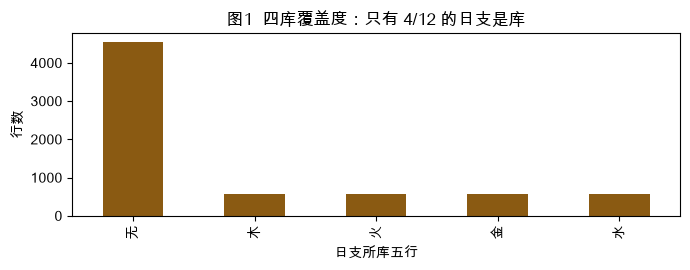

In [39]:
fig, ax = plt.subplots(figsize=(7, 2.8))
k.day_zhi_ku.value_counts().reindex(["无", "木", "火", "金", "水"]).plot.bar(ax=ax, color="#8A5A12")
ax.set_title("图1  四库覆盖度：只有 4/12 的日支是库")
ax.set_xlabel("日支所库五行"); ax.set_ylabel("行数")
plt.tight_layout(); plt.show()

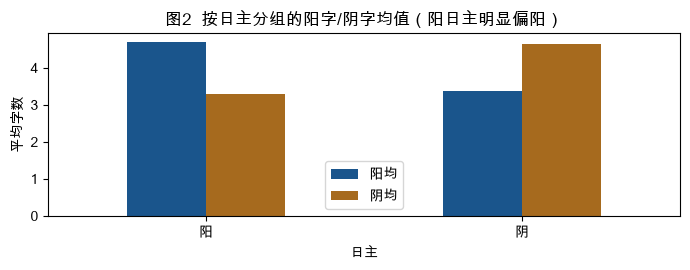

In [40]:
fig, ax = plt.subplots(figsize=(7, 2.8))
g[["阳均", "阴均"]].plot.bar(ax=ax, color=["#1A558C", "#A66A1E"], rot=0)
ax.set_title("图2  按日主分组的阳字/阴字均值（阳日主明显偏阳）")
ax.set_xlabel("日主"); ax.set_ylabel("平均字数")
plt.tight_layout(); plt.show()

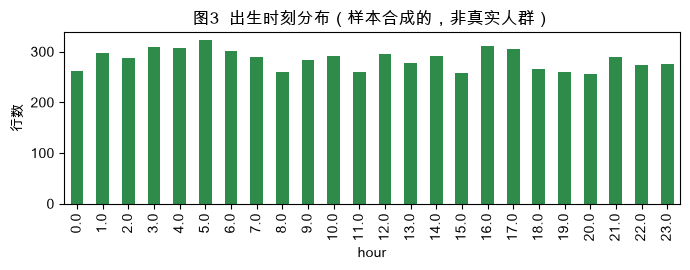

In [41]:
fig, ax = plt.subplots(figsize=(7, 2.8))
known.hour.value_counts().sort_index().plot.bar(ax=ax, color="#2E8B4A")
ax.set_title("图3  出生时刻分布（样本合成的，非真实人群）")
ax.set_xlabel("hour"); ax.set_ylabel("行数")
plt.tight_layout(); plt.show()

**你亲手改一张**：图 3 现在按 `hour` 计数。把它改成按 **`shichen`（时辰）** 分组——
横轴会从 24 个变成 12 个，而且**子和 23 点/0 点的关系**会当场暴露出来：
`shichen` 里同名的两个小时（23 和 0）对应两套不同的日柱规则。改完想想：图还说明同一件事吗？

```python
# 你要改的就是这一行（把 known.hour 换成按 shichen 分组）：
known.hour.value_counts().sort_index().plot.bar(ax=ax, color="#2E8B4A")
```

## 三条结论（我给的版本，你写自己的）

1. **缺失值不能随便填**：这份数据里 480 行没时辰；若统一填 12:00，按 4.04% 的 23 点比例，
   预计 **19.4 行日柱错一天**，而且程序一声不响。空值只表达「不知道」，
   「不是库」这种事实要写 `"无"`——今天两种处理都对上了。
2. **阳日主的盘阳字更多，是结构不是偏差**：对照表手算 8/15=0.533 vs 5/13=0.385，
   加上「干支同奇偶」把日支锁死，所以图 2 的分组差异可以**不靠样本解释**。
   同理，日主 × 四库那张对角线表也是必然，不是 bug。
3. **「缺 X 五行」这句文案没有信息量**：本气口径下几乎 100% 的盘都缺至少一行，
   展开藏干降到 96.3%。要么改口径，要么改成「最弱」而不是「缺」。

⏸ **暂停点 3**：图 + 结论写完，今天的考点就全过了。

## 今天的收尾

**1. `NOTES.md` 三行**（Day 16）。第二行「卡在哪」请写具体的，
比如「merge 完没比行数就往下算」这种，明天才有得复习。

**2. 提交**（存盘 ≠ 提交，错题 #18）。终端里：

```
cd ~/Documents/AI自学/ai-product-journey
git add paipan/core.py paipan/app.py paipan/batch2.py notebooks/16_pandas_agg.ipynb NOTES.md
git status
git commit -m "Day16：改用库的 setSect(1) 统一口径，v2 数据含阴阳与四库，pandas 全表校验"
git push origin main
```

提交信息照你实际做的改写一遍（错题 #20）。`git status` 应该看不到
`charts_v2.csv` 和 `zhi_canggan.csv`——它们被 `.gitignore` 的 `*.csv` 挡住了。

**3. 明天 Day 17 是 FastAPI**：把 `core.py` 变成接口。今天 `count_wx` 返回 10 个键，
明天就是 JSON 的 10 个字段——**数据口径定在算法层，接口和前端跟着走，不许自己再算一遍**（#53）。